# 00 · Data quality, all floors

**Purpose.** One place where the team checks the raw data and signs off the cleaning rules that every
other notebook inherits. Nothing here is floor-specific code: every number comes from
`data/cleaned/`, built by `python scripts/build_clean_data.py` (`src/sbanalytics/pipeline.py`).

**Cleaning rules (applied identically to all 7 floors, `src/sbanalytics/clean.py`)**

| # | Problem | Rule | Why |
|---|---|---|---|
| 1 | Physically impossible values | Outside the registry bounds → NaN | Bounds per point in `registry.py` |
| 2 | Logger glitches found by hand (F4, F5) | Kept as caps → NaN | The floor owners' findings are preserved |
| 3 | Reconnect bursts (e.g. 4,762 kW on a light meter) | > 3×P99.9, ≤ 3 min, rolling median < cap/3 → NaN | A burst is short; a real load step persists |
| 4 | Short gaps | Interpolate interior gaps ≤ 5 min only | Long gaps (outages, blackout) are never filled |
| 5 | Stuck sensors | Flagged in the health table, not deleted | Deleting a frozen-but-plausible meter biases totals more |
| 6 | Hour/day coverage | Hour usable for models if ≥ 48 min present; day if ≥ 20 usable hours | Totals sum what arrived; the flags gate models |

Timestamps are Bangkok local time (no shift); weather is converted UTC → local before the join (§5).

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="obj.round has no effect")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# `pip install -e .` from the repo root makes `sbanalytics` importable; this fallback works without it.
try:
    import sbanalytics
except ImportError:
    import sys
    from pathlib import Path
    sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "sbanalytics").is_dir()) / "src"))

from sbanalytics import data as D, registry as R, viz
viz.setup()
pd.set_option("display.precision", 2)
pd.set_option("display.width", 160)
from sbanalytics import io, anomaly as AN, baseline as B, features as FT, config as C

## 1 · What the pipeline built

Raw vs cleaned energy per floor. Cleaning should move totals by well under 1%; if it moves them more, a rule is doing something it should not.

In [2]:
s = pd.read_csv(C.DATA_CLEANED / "build_summary.csv").set_index("floor")
tbl = pd.DataFrame({
    "first reading": s["first"], "last reading": s["last"],
    "minutes with data": s.rows_with_data,
    **{f"{ch.upper()} kWh (raw)": s[f"{ch}_kwh_raw"].round(0) for ch in ("ac", "light", "plug")},
    **{f"{ch.upper()} change %": ((s[f"{ch}_kwh_clean"] / s[f"{ch}_kwh_raw"] - 1) * 100).round(2) for ch in ("ac", "light", "plug")},
    "minutes changed": s.minutes_changed,
})
tbl

,first reading,last reading,minutes with data,AC kWh (raw),LIGHT kWh (raw),PLUG kWh (raw),AC change %,LIGHT change %,PLUG change %,minutes changed
floor,,,,,,,,,,
1,2018-07-01 00:00:00,2019-12-31 23:59:00,789493,435621.0,722791.0,239417.0,0.01,-0.00,0.06,2822
2,2018-07-01 00:00:00,2019-12-31 23:59:00,789692,284888.0,58618.0,21491.0,0.05,0.02,0.00,43226
3,2018-07-01 00:00:00,2019-12-31 23:59:00,731050,162407.0,74697.0,17589.0,0.06,0.01,-0.13,55768
4,2018-07-01 00:00:00,2019-12-31 23:59:00,756772,180045.0,56802.0,27930.0,0.06,0.28,0.05,51093
5,2018-07-01 00:00:00,2019-12-31 23:59:00,783828,177914.0,74136.0,22390.0,0.24,0.35,0.04,74542
6,2018-07-01 00:00:00,2019-10-22 13:27:00,688318,146840.0,82617.0,19078.0,0.07,0.10,0.04,48983
7,2018-07-01 00:00:00,2019-12-31 23:59:00,789618,293302.0,74800.0,9234.0,0.04,0.17,0.13,69167


## 2 · Coverage: which data exist, and when

Monthly completeness (% of minutes received) by floor and channel. The two features every analysis must respect are visible at a glance: the **indoor-sensor blackout from mid-Sep 2018 to early Mar 2019 on every floor**, and the **F6 file ending on 22 Oct 2019**.

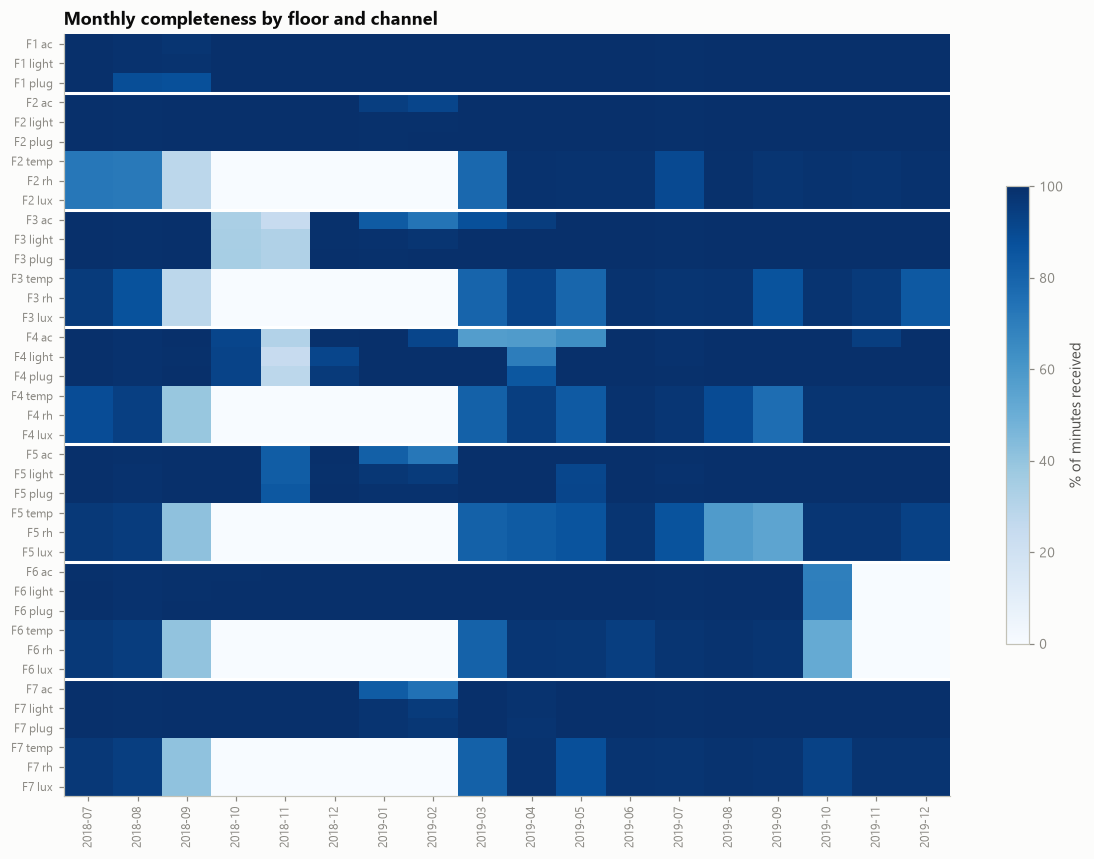

In [3]:
H = D.load_health(None)
H["month"] = H.day.dt.to_period("M")
cov = (H.groupby(["floor", "channel", "month"]).completeness.mean().unstack("month"))
order = ["ac", "light", "plug", "temp", "rh", "lux"]
cov = cov.reindex([(f, c) for f in C.FLOORS for c in order if (f, c) in cov.index])

fig, ax = plt.subplots(figsize=(13, 9))
im = ax.imshow(cov.to_numpy(), aspect="auto", cmap=viz.SEQUENTIAL, vmin=0, vmax=100)
ax.set_yticks(range(len(cov)), [f"F{f} {c}" for f, c in cov.index], fontsize=8)
ax.set_xticks(range(len(cov.columns)), [str(m) for m in cov.columns], rotation=90, fontsize=8)
ax.grid(False)
for i, (f, c) in enumerate(cov.index):
    if i and cov.index[i - 1][0] != f:
        ax.axhline(i - 0.5, color="white", lw=2)
fig.colorbar(im, ax=ax, label="% of minutes received", shrink=0.6)
ax.set_title("Monthly completeness by floor and channel")
viz.save(fig, "00_coverage_heatmap")

### Outage register

Every stretch of ≥ 3 consecutive days in which a floor's channel received < 5% of its minutes. This is the list of periods no analysis may treat as zero consumption.

In [4]:
day = H.groupby(["floor", "channel", "day"]).completeness.mean().reset_index()
day["off"] = day.completeness < 5
rows = []
for (f, ch), g in day.groupby(["floor", "channel"]):
    g = g.sort_values("day")
    run = (g.off != g.off.shift()).cumsum()
    for _, e in g[g.off].groupby(run[g.off]):
        if len(e) >= 3:
            rows.append({"floor": f, "channel": ch, "from": e.day.min().date(), "to": e.day.max().date(), "days": len(e)})
outages = pd.DataFrame(rows).sort_values(["floor", "from", "channel"])
C.TABLES.mkdir(parents=True, exist_ok=True)
outages.to_csv(C.TABLES / "outage_register.csv", index=False)
outages

,floor,channel,from,to,days
0,2,lux,2018-09-13,2019-03-05,174
1,2,rh,2018-09-13,2019-03-05,174
2,2,temp,2018-09-13,2019-03-05,174
5,3,lux,2018-09-13,2019-03-05,174
7,3,rh,2018-09-13,2019-03-05,174
8,3,temp,2018-09-13,2019-03-05,174
3,3,ac,2018-10-12,2018-11-20,40
4,3,light,2018-10-12,2018-11-20,40
6,3,plug,2018-10-12,2018-11-20,40
11,4,lux,2018-09-15,2019-03-05,172


## 3 · What cleaning changed

Minutes changed per floor and rule (full detail, including first/last timestamp of every change, is in `data/cleaned/cleaning_log.csv`).

In [5]:
log = pd.read_csv(C.DATA_CLEANED / "cleaning_log.csv")
display(log.pivot_table(index="floor", columns="rule", values="minutes", aggfunc="sum", fill_value=0))
log[log.rule != "interpolated"].sort_values("minutes", ascending=False).head(10)[["floor", "column", "rule", "minutes", "detail"]]

rule,glitch_cap,interpolated,range,spike
floor,,,,
1,0,2723,96,3
2,0,43186,0,40
3,0,55427,14,327
4,9,51060,1,23
5,26,74396,39,81
6,0,48918,0,65
7,0,69157,0,10


,floor,column,rule,minutes,detail
2,1,z2_AC1(kW),range,84,"outside [0, 80] kW"
88,3,z3_Plug(kW),spike,59,"> 2.55 kW, <= 3 min"
92,3,z4_Light(kW),spike,45,"> 10.47 kW, <= 3 min"
103,3,z5_Plug(kW),spike,40,"> 3.84 kW, <= 3 min"
101,3,z5_Light(kW),spike,37,"> 9.21 kW, <= 3 min"
94,3,z4_Plug(kW),spike,36,"> 5.28 kW, <= 3 min"
168,5,z2_Light(kW),spike,35,"> 14.13 kW, <= 3 min"
86,3,z3_Light(kW),spike,33,"> 4.98 kW, <= 3 min"
70,3,z1_Light(kW),spike,32,"> 18.15 kW, <= 3 min"
72,3,z1_Plug(kW),spike,26,"> 5.94 kW, <= 3 min"


**Example: the largest spike in the dataset.** F1 `z3_Light` reads 4,762 kW for a single minute — about 50× its normal maximum. The rule removes the burst and leaves the surrounding load untouched.

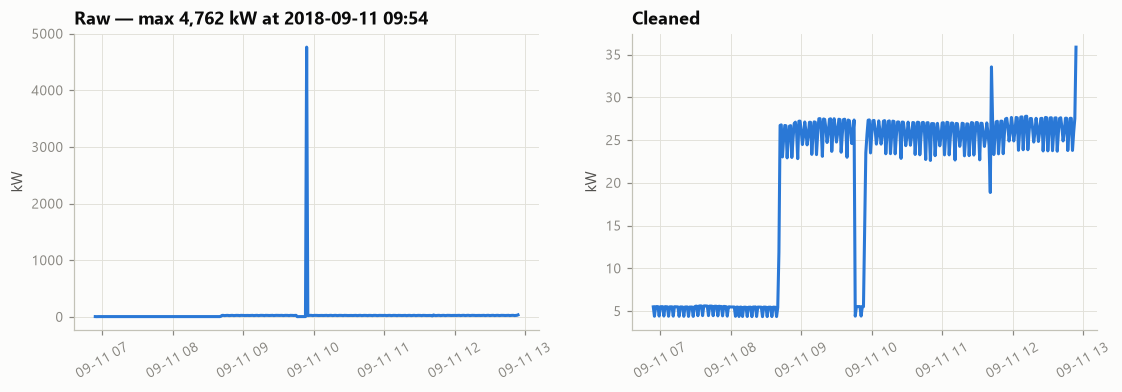

In [6]:
raw1 = io.load_raw(1)
col = "z3_Light(kW)"
t = raw1[col].idxmax()
lo, hi = t - pd.Timedelta(hours=3), t + pd.Timedelta(hours=3)
clean1 = D.load_minute(1, lo, hi, columns=[col])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharex=True)
axes[0].plot(raw1.loc[lo:hi, col], color=viz.CATEGORICAL[0])
axes[0].set_title(f"Raw — max {raw1[col].max():,.0f} kW at {t:%Y-%m-%d %H:%M}")
axes[1].plot(clean1[col], color=viz.CATEGORICAL[0])
axes[1].set_title("Cleaned")
for a in axes:
    a.set_ylabel("kW"); a.tick_params(axis="x", rotation=30)
viz.save(fig, "00_spike_example")
del raw1

## 4 · Meter roles: dead, residual and always-on units

Per AC meter over the whole record. *Dead* = never draws power; *always-on* = running in > 80% of night hours (01:00–05:00). These became role overrides in `registry.py` and are also candidate recommendations (analysis/06).

In [7]:
hp = D.load_hourly_points()
units = AN.unit_status(hp)
units.to_csv(C.TABLES / "ac_unit_status.csv", index=False)
units[units.status != "scheduled"].round(3)

,floor,zone,column,role,kwh,hours,on_share,night_on_share,floor_share,status
0,1,z2,z2_AC1(kW),primary,368478.88,13152,7.76e-01,9.87e-01,0.85,always-on
2,1,z2,z2_AC3(kW),residual,109.33,13152,0.00e+00,0.00e+00,0.00,rarely runs
3,1,z2,z2_AC4(kW),residual,96.61,13152,0.00e+00,0.00e+00,0.00,rarely runs
5,2,z2,z2_AC1(kW),primary,77045.85,12677,9.43e-01,9.98e-01,0.27,always-on
15,2,z2,z2_AC6(kW),primary,7710.68,13165,7.85e-01,9.98e-01,0.03,always-on
10,2,z2,z2_AC14(kW),residual,93.71,13165,9.00e-03,0.00e+00,0.00,rarely runs
8,2,z2,z2_AC12(kW),residual,92.33,13165,9.00e-03,0.00e+00,0.00,rarely runs
7,2,z2,z2_AC11(kW),dead,0.00,13165,0.00e+00,0.00e+00,0.00,dead
20,3,z1,z1_AC1(kW),residual,26.74,12064,2.00e-03,0.00e+00,0.00,rarely runs
29,4,z1,z1_AC3(kW),residual,12.40,10403,2.00e-03,0.00e+00,0.00,rarely runs


## 5 · Clocks: are the timestamps local time?

**Weather.** The ERA5 file is UTC. After converting to Bangkok time, mean solar radiation should peak at 11:00–12:00 (solar noon ≈ 12:15).

In [8]:
w = D.load_weather()
solar = w.groupby(w.ts.dt.hour).out_solar.mean()
print(f"Solar radiation peaks in the hour starting {solar.idxmax()}:00 local time")

Solar radiation peaks in the hour starting 11:00 local time


**Building meters.** On an office floor, load runs ahead of the afternoon temperature peak, so the correlation between load and outdoor temperature is highest at a small negative lag. A floor whose clock were shifted would stand out with a very different best lag.

,best lag (h),corr at best lag,corr at lag 0
1,7,0.55,-0.18
2,-2,0.54,0.45
3,-2,0.47,0.36
4,-2,0.49,0.36
5,-2,0.49,0.38
6,-2,0.52,0.40
7,-2,0.50,0.41


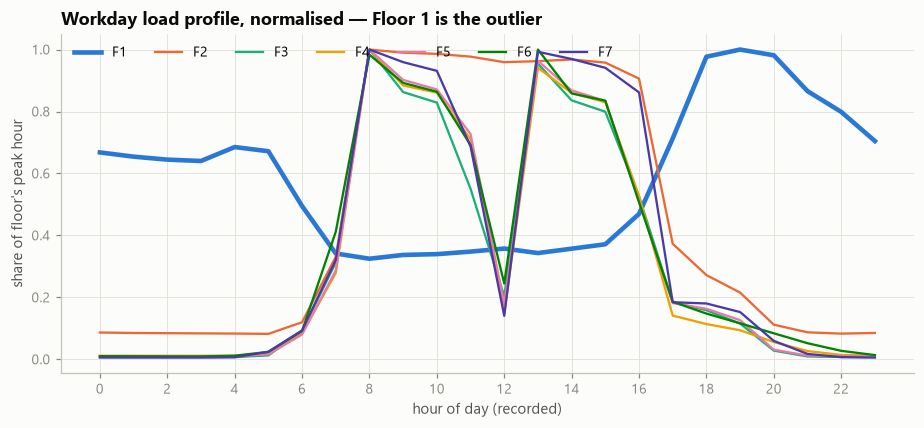

In [9]:
fh = B.floor_hourly(D.load_hourly(None))
lags = {}
for f, g in fh.groupby("floor"):
    g = g.set_index("ts").asfreq("h")
    lags[f] = {k: g.total_kwh.corr(g.out_temp.shift(k)) for k in range(-12, 13)}
lag_tbl = pd.DataFrame(lags).T
summary = pd.DataFrame({"best lag (h)": lag_tbl.idxmax(axis=1), "corr at best lag": lag_tbl.max(axis=1), "corr at lag 0": lag_tbl[0]})
display(summary)

prof = fh[fh.day_type == "workday"].groupby(["floor", "hour"]).total_kwh.mean().unstack("floor")
fig, ax = plt.subplots(figsize=(10, 4))
for f in prof.columns:
    ax.plot(prof.index, prof[f] / prof[f].max(), color=viz.FLOOR_COLORS[f], label=f"F{f}", lw=3 if f == 1 else 1.5)
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("hour of day (recorded)"); ax.set_ylabel("share of floor's peak hour")
ax.set_title("Workday load profile, normalised — Floor 1 is the outlier")
ax.legend(ncol=7, loc="upper left")
viz.save(fig, "00_workday_profiles")

In [10]:
dow = fh[fh.floor == 1].groupby([fh.ts.dt.dayofweek.rename("weekday"), "hour"]).total_kwh.mean().unstack()
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow.round(0)

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Mon,112.0,111.0,109.0,108.0,116.0,113.0,81.0,63.0,62.0,63.0,...,67.0,71.0,95.0,132.0,173.0,175.0,171.0,149.0,139.0,125.0
Tue,123.0,120.0,119.0,118.0,125.0,122.0,93.0,66.0,61.0,68.0,...,70.0,71.0,90.0,126.0,172.0,178.0,175.0,150.0,139.0,123.0
Wed,118.0,114.0,112.0,112.0,121.0,119.0,89.0,59.0,57.0,58.0,...,65.0,65.0,75.0,120.0,169.0,175.0,171.0,155.0,146.0,127.0
Thu,123.0,119.0,118.0,118.0,126.0,125.0,93.0,63.0,58.0,61.0,...,65.0,69.0,81.0,126.0,173.0,177.0,175.0,161.0,150.0,131.0
Fri,126.0,125.0,123.0,122.0,129.0,127.0,92.0,63.0,62.0,61.0,...,63.0,66.0,88.0,134.0,185.0,189.0,186.0,160.0,144.0,128.0
Sat,123.0,121.0,118.0,119.0,127.0,122.0,91.0,81.0,78.0,80.0,...,82.0,83.0,95.0,107.0,147.0,152.0,150.0,130.0,127.0,116.0
Sun,115.0,114.0,113.0,112.0,120.0,118.0,86.0,78.0,82.0,85.0,...,84.0,82.0,92.0,102.0,146.0,147.0,146.0,122.0,121.0,113.0


**Reading the Floor 1 evidence**

* F2–F7 all correlate best with outdoor temperature at the same small negative lag and share the
  08:00 start, 12:00 lunch shutdown and 16:30 finish: their clocks agree with each other and with local time.
* F1 peaks in the evening (17:00–23:00) and is quiet through the working day; its best lag differs
  from the other floors by about 9 hours. A 7-hour clock error (the F1 notebook's hypothesis) would explain the lag,
  and the lower Monday 00:00–06:00 load is what a shift would produce (those hours would be Sunday evening).
* But a shift does not make F1 look like an office: its *weekend* daytime load is higher than its weekday
  daytime load, and its AC never switches off. F1 is a different kind of space (lighting is its largest end use).

**Decision.** No timestamp shift is applied (the evidence is not conclusive, and a wrong shift would corrupt
every F1 result). F1 is kept in all energy totals but **excluded from schedule-based KPIs** (after-hours share,
baseload ratio, occupied-hour comfort) and from schedule-based anomaly rules. Facilities management should
confirm F1's use and its logger clock — this is in the recommendations.

## 6 · Measured AC schedules

Read off the meter (`features.measure_ac_hours`: hours in which the floor's AC is on for at least half of workdays) and compared with what `registry.AC_ON_HOURS_BY_FLOOR` declares.

In [11]:
h_all = D.load_hourly(None)
sched = pd.DataFrame({
    "measured": {f: FT.measure_ac_hours(h_all, f) for f in C.FLOORS},
    "registry": {f: R.ac_on_hours(f) for f in C.FLOORS},
})
sched["agree"] = sched.measured.astype(str) == sched.registry.astype(str)
sched

,measured,registry,agree
1,[],"[8, 9, 10, 11, 12, 13, 14, 15, 16]",False
2,"[8, 9, 10, 11, 12, 13, 14, 15, 16]","[8, 9, 10, 11, 12, 13, 14, 15, 16]",True
3,"[8, 9, 10, 11, 13, 14, 15, 16]","[8, 9, 10, 11, 13, 14, 15, 16]",True
4,"[8, 9, 10, 11, 13, 14, 15, 16]","[8, 9, 10, 11, 13, 14, 15, 16]",True
5,"[8, 9, 10, 11, 13, 14, 15, 16]","[7, 8, 9, 10, 11, 13, 14, 15, 16]",False
6,"[8, 9, 10, 11, 13, 14, 15, 16]","[8, 9, 10, 11, 13, 14, 15, 16]",True
7,"[8, 9, 10, 11, 13, 14, 15, 16]","[8, 9, 10, 11, 13, 14, 15, 16]",True


F2–F7 run AC 08:00–11:59 and 13:00–16:59 on workdays; F2 has no lunch shutdown. F5 keeps the dashboard's hand-validated list, which also counts the partial hour 07:00. F1 has no schedule (AC runs around the clock), so it gets the nominal 08–17 window.

## 7 · Metering re-assignments between zones

A known trap on F5: on 2019-09-27 cooling energy moved from the z4 meter to the z2 meter (z4 −19%, z2 +10%) while their sum barely changed — a CT re-assignment, not a change in demand. A single-zone step test cannot find this: seasonal swings (e.g. −25% from the mid-May semester break) are larger. The signature to look for is **two zones moving in opposite directions while their sum stays flat**. Scan every floor and zone pair over Mar–Dec 2019 (6-week medians of weekly occupied AC either side of each week).

In [12]:
import itertools
occ = h_all[h_all.is_workday & (h_all.ts >= "2019-03-07")]
occ = occ[[hr in R.ac_on_hours(int(f)) for f, hr in zip(occ.floor, occ.hour)]]
wk = occ.groupby(["floor", "zone", pd.Grouper(key="ts", freq="W-MON")]).ac_kwh.mean().unstack("zone")
rows = []
for f, w in wk.groupby(level=0):
    w = w.droplevel(0).dropna(axis=1, how="all")
    w = w.loc[:, w.mean() > 1]
    for a, b in itertools.combinations(w.columns, 2):
        for i in range(6, len(w) - 6):
            bef, aft = w.iloc[i - 6:i], w.iloc[i:i + 6]
            ra, rb = aft[a].median() / bef[a].median(), aft[b].median() / bef[b].median()
            rs = (aft[a] + aft[b]).median() / (bef[a] + bef[b]).median()
            if (ra - 1) * (rb - 1) < 0:
                rows.append({"floor": f, "pair": f"{a}/{b}", "week": w.index[i].date(), "zone a after/before": ra,
                             "zone b after/before": rb, "pair sum after/before": rs,
                             "score": min(abs(ra - 1), abs(rb - 1)) - abs(rs - 1)})
transfers = (pd.DataFrame(rows).sort_values("score", ascending=False)
             .drop_duplicates(["floor", "pair"]).groupby("floor").head(2))
transfers.to_csv(C.TABLES / "candidate_meter_transfers.csv", index=False)
transfers

,floor,pair,week,zone a after/before,zone b after/before,pair sum after/before,score
181,6,z1/z5,2019-06-10,1.16,0.69,1.00,0.16
171,6,z1/z4,2019-06-10,1.16,0.83,0.98,0.14
108,5,z1/z4,2019-07-15,0.88,1.19,0.99,0.11
127,5,z2/z4,2019-10-07,1.12,0.87,0.99,0.11
46,4,z1/z2,2019-05-13,0.90,1.33,1.00,0.10
228,7,z4/z5,2019-10-14,1.13,0.88,1.04,0.08
27,3,z1/z5,2019-05-06,1.16,0.88,0.97,0.08
218,7,z2/z5,2019-10-14,1.09,0.88,1.03,0.06
79,4,z2/z4,2019-05-13,1.33,0.91,1.03,0.05
35,3,z2/z4,2019-07-15,0.92,1.06,0.99,0.04


**Reading it.** Score = the smaller of the two opposite moves minus the change in their sum. The known F5 z2/z4
transfer appears (dated to the first full 6-week window after 2019-09-27), which validates the scan. The strongest
signature in the building is **F6 z1/z5 around June 2019**; others above ~0.08 are candidates. Each candidate should be
confirmed against the minute data (does it happen within one afternoon, as F5's did?) and, if confirmed, added to
`registry.CHANGE_POINTS` so zone-level baselines do not train across it. Floor-level baselines (analysis/02) are
unaffected, because a transfer between meters leaves the floor total unchanged.